# Desenvolvimento de IA para Análise Preditiva
## Mini-Projeto Avaliativo — Módulo 2 (Semana 05)
### Pipeline Preditivo Multiclasse: Benchmark MNIST, Testes de Generalização OOD e Inferência em Imagens Reais
---
**Autor:** Susej Gonzalez. 

**Dataset:** MNIST (*Modified National Institute of Standards and Technology*) — 70.000 amostras (28x28 pixels).  
**Ambiente:** Python 3.12 | Scikit-Learn | TensorFlow/Keras | OpenCV | Seaborn

In [1]:
## Importação de bibliotecas essenciais

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

## Configuração visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid")
%matplotlib inline

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!



# Fase 1: Carregamento e Análise Exploratória de Imagens (EDA)
Nesta etapa inicial:
1. Importamos a base de dados oficial **MNIST (mnist_784)** via OpenML.
2. Inspecionamos as dimensões das matrizes de características ($X$) e vetor de rótulos ($y$).
3. Verificamos e comprovamos o balanceamento estatístico entre as 10 classes (dígitos 0 a 9).
4. Construímos uma grade visual $2 \times 5$ com amostras nítidas de cada dígito.
5. Discutimos a representação digital de imagens (escala de cinza 0–255 e vetorização $28 \times 28 \rightarrow 784$).


In [2]:
print("Carregando o dataset MNIST (mnist_784) via OpenML...")
# essa linha de codigo conecta-se ao repositorio cientifico OpenML, carrega o dataset estandar mnist_784 e o 
# almacena na memoria cache co computador para que a proxima vez carregue ao instante.
# as_frame=False`: Instrui o Scikit-Learn a fornecer arrays NumPy em vez de um DataFrame do Pandas.
# Ao trabalhar com imagens, os arrays NumPy consomem menos memória e realizam cálculos matemáticos 
# até 10 vezes mais rápido. `parser='auto'`: Usa o analisador sintático otimizado para leitura para 
# evitar avisos de compatibilidade.
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')

# Separação dos atributos previsores (X) e do vetor de rótulos/alvo (y)
# X (variaveis independentes / feature) é a matriz que contem os valores dos pixeis das 70.000 imagens 
# y (variavel alvo / target) é o vector que contem a etiqueta ou resposta correcra do que é cada imagem. 
X, y = mnist.data, mnist.target.astype(np.uint8)

# esta tratativa é importante porque OpenML carrega as etiquetas como texto, ai  .astype(np.uint8) 
# converte números inteiros sem sinal de 8 bits ($0, 1, 2 \dots 9$). Isso é indispensável para que os
# algoritmos de Machine Learning possam processá-los numericamente e calcular funções de custo ou matrizes
# de confusão.


print("\n=== RESUMO DIMENSIONAL DOS DADOS ===")
print(f"• Formato da matriz de características (X): {X.shape} -> 70.000 imagens com 784 pixels cada")
print(f"• Formato do vetor de classes/rótulos (y): {y.shape} -> 70.000 rótulos correspondentes")
print(f"• Classes únicas existentes: {np.unique(y)}")
print(f"• Tipo de dado dos pixels em X: {X.dtype}")
print(f"• Tipo de dado dos rótulos em y: {y.dtype}")
print(f"• Intervalo de intensidade original dos pixels: [{X.min():.0f}, {X.max():.0f}]")






Carregando o dataset MNIST (mnist_784) via OpenML...

=== RESUMO DIMENSIONAL DOS DADOS ===
• Formato da matriz de características (X): (70000, 784) -> 70.000 imagens com 784 pixels cada
• Formato do vetor de classes/rótulos (y): (70000,) -> 70.000 rótulos correspondentes
• Classes únicas existentes: [0 1 2 3 4 5 6 7 8 9]
• Tipo de dado dos pixels em X: int64
• Tipo de dado dos rótulos em y: uint8
• Intervalo de intensidade original dos pixels: [0, 255]


In [3]:
X[700]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,  98, 224,  42,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  3

In [4]:
y

array([5, 0, 4, ..., 4, 5, 6], shape=(70000,), dtype=uint8)

### 1.1 Verificação e Comprovação do Balanceamento das Classes
Em problemas de classificação multiclasse, é fundamental averiguar se há desbalanceamento de classes, o que poderia enviesar os algoritmos de aprendizado supervisionado.


=== DISTRIBUIÇÃO DAS CLASSES NO DATASET MNIST ===


,Dígito (Classe),Quantidade de Amostras,Proporção (%)
0,0,6903,9.86
1,1,7877,11.25
2,2,6990,9.99
3,3,7141,10.20
4,4,6824,9.75
5,5,6313,9.02
6,6,6876,9.82
7,7,7293,10.42
8,8,6825,9.75
9,9,6958,9.94


findfont: Failed to find font weight semibold, now using 700.


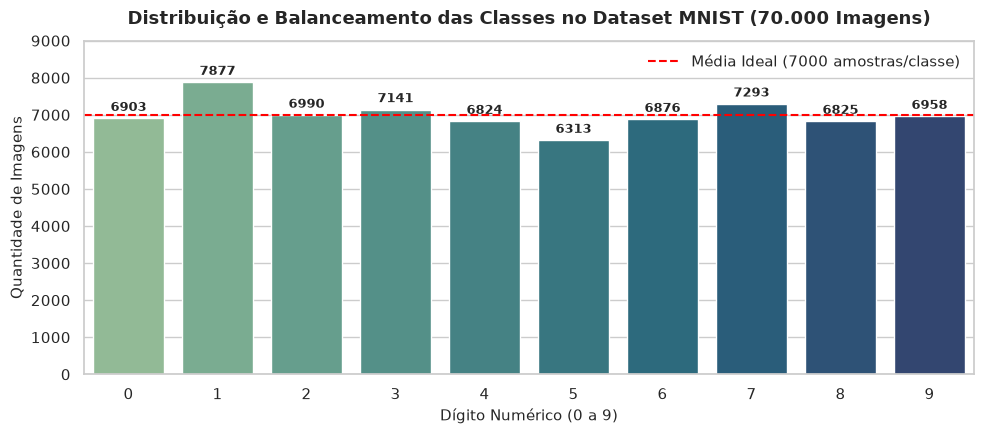

In [5]:
# 1. Contagem da frequência absoluta de cada dígito (0 a 9)
classes_unicas, contagens = np.unique(y, return_counts=True)

# 2. Construção de um DataFrame elegante para apresentar a tabela quantitativa
df_balanceamento = pd.DataFrame({
    'Dígito (Classe)': classes_unicas,
    'Quantidade de Amostras': contagens,
    'Proporção (%)': np.round((contagens / len(y)) * 100, 2)
})

print("=== DISTRIBUIÇÃO DAS CLASSES NO DATASET MNIST ===")
display(df_balanceamento)

# 3. Visualização gráfica da distribuição de classes com Seaborn
plt.figure(figsize=(10, 4.5))
palette_colors = sns.color_palette("crest", len(classes_unicas))
barplot = sns.barplot(
    x='Dígito (Classe)',
    y='Quantidade de Amostras',
    data=df_balanceamento,
    palette=palette_colors,
    hue='Dígito (Classe)',
    legend=False
)

# 4. Linha de referência da média teórica ideal (7.000 amostras por classe)
media_ideal = len(y) / len(classes_unicas)
plt.axhline(media_ideal, color='red', linestyle='--', linewidth=1.5, label=f'Média Ideal ({media_ideal:.0f} amostras/classe)')

plt.title("Distribuição e Balanceamento das Classes no Dataset MNIST (70.000 Imagens)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Dígito Numérico (0 a 9)", fontsize=11)
plt.ylabel("Quantidade de Imagens", fontsize=11)
plt.ylim(0, 9000)

# 5. Inserir o valor numérico exato acima de cada barra do gráfico
for i, count in enumerate(contagens):
    barplot.text(i, count + 120, f"{count}", ha='center', va='bottom', fontsize=9, fontweight='semibold')

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


### 1.2 Grade Visual de Amostras ($2 \times 5$) com Matplotlib
Exibição de exemplos representativos de cada um dos 10 dígitos (0 a 9) com seus respectivos rótulos originais para inspeção visual da caligrafia humana.

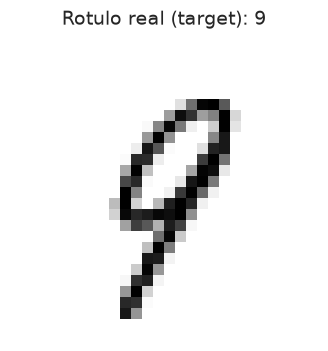

In [6]:
# aqui decide fazer a brincadeira para testar como o prof. mostrou na aula.
# NOTA TEXTUAL DA AULA: na practica para disenharmos a imagem, preparamos o vetor de 784 numeros e fazemos o processo inverso: 
# transformamos de volta para a matriz de 28x28 com o .reshape(28, 28) 
digito_exemplo = X[22]
digito_imagem = digito_exemplo.reshape(28, 28)

plt.figure(figsize=(4, 4))
plt.imshow(digito_imagem, cmap='binary')  # cmap='binary' mostra preto no branco.compile
plt.title(f'Rotulo real (target): {y[22]}', fontsize=14)
plt.axis('off') #oculta os eixos cartecianos
plt.show()

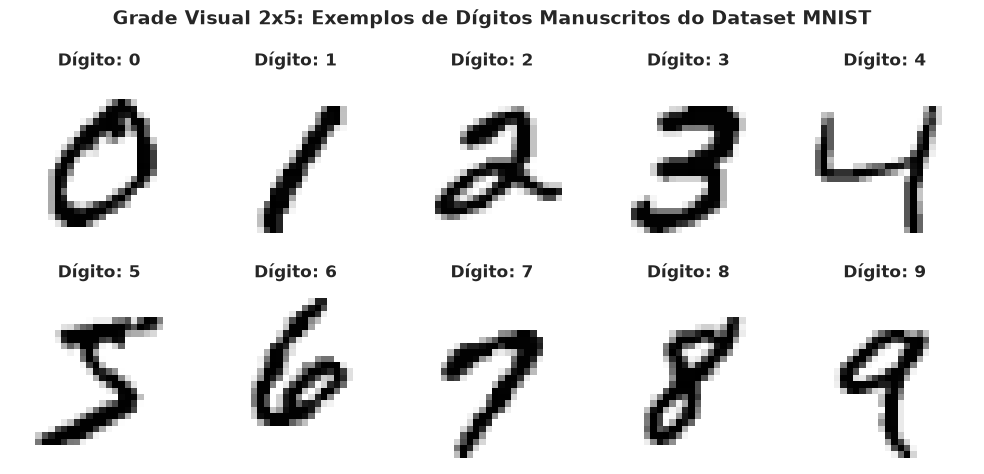

In [7]:
# 1. Localiza el índice de la primera ocurrencia de cada dígito (0 a 9) en y
indices_digitos = [np.where(y == d)[0][0] for d in range(10)]

# 2. Crea una figura con 2 filas y 5 columnas de sub-gráficos
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

#  A função enumerate() retorna duas coisas ao mesmo tempo em cada volta do ciclo:
# i: O número de volta 
# ax: o sub-gráfico (a janelinha onde va a dibujar).
for d, ax in enumerate(axes.flat):  # .flat é uma propriedade do NumPy que "aplana" uma quadra 2D e a converte em 
# uma lista simples de 10 janelas seguidas
    idx = indices_digitos[d]
    ax.imshow(X[idx].reshape(28, 28), cmap='binary')
    ax.set_title(f'Dígito: {d}', fontsize=12, fontweight='bold')
    ax.axis('off')

plt.suptitle("Grade Visual 2x5: Exemplos de Dígitos Manuscritos do Dataset MNIST", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### 1.3 Entendendo a Estrutura das Imagens e dos Dados

Para entender como o computador "enxerga" essas imagens e como preparamos os dados para os modelos, precisamos compreender dois conceitos simples:

---

#### 1. O que significa a escala de pixels de 0 a 255?
* Cada imagem é formada por pequenos quadradinhos chamados **pixels**.
* Como as fotos são em preto e branco (tons de cinza), cada pixel guarda apenas a intensidade da luz usando 1 byte de memória (valores de **0 a 255**):
  * **0 (Preto / Fundo):** Significa ausência de tinta. É o fundo escuro da imagem.
  * **255 (Branco / Traço):** Significa o traço forte da caneta onde a pessoa escreveu o número.
  * **Valores entre 1 e 254 (Tons de Cinza):** São as bordas suaves do traço da caneta, que dão forma ao desenho para que não fique serrilhado.

---

#### 2. Por que transformamos a imagem 2D ($28 \times 28$) em 784 números ($1\text{D}$)?
* **A imagem original:** É uma grade quadrada com **28 linhas e 28 colunas**. Se multiplicarmos $28 \times 28$, temos exatamente **784 pixels** no total.
* **O problema dos modelos:** Algoritmos clássicos de Machine Learning (como SVM, Random Forest e Redes Neurais simples) funcionam como uma planilha do Excel: eles precisam que cada exemplo seja uma linha e cada característica seja uma coluna.
* **A solução (Achatamento / *Flattening*):** Nós "esticamos" ou desenrolamos a imagem quadrada em uma única fila de 784 números seguidos.
  
> **Analogia simples:** É como pegar uma folha quadriculada de 28x28 e recortar linha por linha para colar tudo em uma única fita comprida de 784 números. Assim, cada pixel vira uma coluna (*feature*) que o modelo consegue analisar.


---
# Fase 2: Pipeline de Pré-processamento e Divisão dos Dados

Nesta etapa preparamos os dados para o treinamento dos modelos:
1. **Divisão Estratificada (Train/Val/Test Split 70/10/20):** Separação em 70% treino (49.000 amostras), 10% validação (7.000 amostras) e 20% teste (14.000 amostras) com `stratify=y` para manter a proporção exata de cada dígito nos três conjuntos.
2. **Normalização / Escalonamento:** Redimensionamento dos pixels da escala inteira $[0, 255]$ para a escala contínua $[0.0, 1.0]$.
3. **Justificativa Técnica:** Discussão sobre convergência do gradiente, estabilidade numérica e prevenção de vazamento de dados (*Data Leakage*).


In [8]:
# 1. Primeira divisão: Separa 20% para Teste Final (14.000) e 80% temporário para Treino+Val (56.000)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 2. Segunda divisão: Separa 12.5% dos 80% para Validação (0.125 * 0.80 = 10% do total = 7.000)
# Ficando 70% para Treino definitivo (49.000)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.125, stratify=y_train, random_state=42
)
print("=== DIMENSÕES APÓS A DIVISÃO ESTRATIFICADA (70/10/20) ===")
print(f"• X_treino:     {X_train.shape} | y_treino:     {y_train.shape} (70% do dataset = 49.000)")
print(f"• X_validacao:  {X_val.shape}   | y_validacao:  {y_val.shape}   (10% do dataset =  7.000)")
print(f"• X_teste:      {X_test.shape}  | y_teste:      {y_test.shape}  (20% do dataset = 14.000)")


=== DIMENSÕES APÓS A DIVISÃO ESTRATIFICADA (70/10/20) ===
• X_treino:     (49000, 784) | y_treino:     (49000,) (70% do dataset = 49.000)
• X_validacao:  (7000, 784)   | y_validacao:  (7000,)   (10% do dataset =  7.000)
• X_teste:      (14000, 784)  | y_teste:      (14000,)  (20% do dataset = 14.000)


In [9]:
# 2. Comprovação matemática de que a proporção de cada dígito é idêntica nos 3 subconjuntos
proporcao_treino = np.bincount(y_train) / len(y_train) * 100
proporcao_val    = np.bincount(y_val)   / len(y_val)   * 100
proporcao_teste  = np.bincount(y_test)  / len(y_test)  * 100
df_estratificacao = pd.DataFrame({
    'Dígito': range(10),
    'Treino (70%)': np.round(proporcao_treino, 2),
    'Validação (10%)': np.round(proporcao_val, 2),
    'Teste (20%)': np.round(proporcao_teste, 2)
})
print("\n=== COMPROVAÇÃO DE ESTRATIFICAÇÃO (PROPORÇÃO PERCENTUAL POR DÍGITO) ===")
display(df_estratificacao)


=== COMPROVAÇÃO DE ESTRATIFICAÇÃO (PROPORÇÃO PERCENTUAL POR DÍGITO) ===


,Dígito,Treino (70%),Validação (10%),Teste (20%)
0,0,9.86,9.86,9.86
1,1,11.25,11.26,11.25
2,2,9.99,9.99,9.99
3,3,10.20,10.20,10.20
4,4,9.75,9.74,9.75
5,5,9.02,9.01,9.02
6,6,9.82,9.83,9.82
7,7,10.42,10.41,10.42
8,8,9.75,9.76,9.75
9,9,9.94,9.94,9.94


In [10]:
# 3. Normalização dos pixels para a escala [0.0, 1.0] dividindo por 255.0
X_train = X_train / 255.0
X_val   = X_val   / 255.0
X_test  = X_test  / 255.0
print("=== VERIFICAÇÃO DA NORMALIZAÇÃO ===")
print(f"• X_treino    — Min: {X_train.min():.2f} | Max: {X_train.max():.2f} | Tipo: {X_train.dtype}")
print(f"• X_validacao — Min: {X_val.min():.2f}   | Max: {X_val.max():.2f}   | Tipo: {X_val.dtype}")
print(f"• X_teste     — Min: {X_test.min():.2f}  | Max: {X_test.max():.2f}  | Tipo: {X_test.dtype}")

=== VERIFICAÇÃO DA NORMALIZAÇÃO ===
• X_treino    — Min: 0.00 | Max: 1.00 | Tipo: float64
• X_validacao — Min: 0.00   | Max: 1.00   | Tipo: float64
• X_teste     — Min: 0.00  | Max: 1.00  | Tipo: float64


### 4. Por que precisamos de 3 conjuntos e normalizar os dados?

Nesta etapa estruturamos o pipeline de dados com rigor metodológico:

---
#### 1. Divisão em Três Vias (70% Treino / 10% Validação / 20% Teste):
* **Treino (49.000 amostras):** Utilizado exclusivamente para os algoritmos aprenderem os padrões e ajustarem seus parâmetros internos (pesos, divisões das árvores).
* **Validação (7.000 amostras):** Utilizado para comparar diferentes combinações de hiperparâmetros (como `max_depth`, `learning_rate`, `C`) e selecionar a melhor configuração de cada família.
* **Teste (14.000 amostras):** Mantido estritamente isolado ("sob cofre"). É utilizado apenas na Fase 4 para a avaliação final e imparcial de desempenho.

---
#### 2. Prevenção de Vazamento de Dados (*Data Leakage*):
* Se utilizássemos o conjunto de **Teste** para ajustar hiperparâmetros, estaríamos enviesando a escolha e falseando a capacidade real de generalização do modelo.
* A normalização por `255.0` é uma transformação estática baseada no valor máximo teórico de pixels em 8 bits ($2^8 - 1 = 255$), não havendo compartilhamento de estatísticas entre os conjuntos.


---
# Fase 3: Implementação e Treinamento dos Modelos Preditivos

Nesta etapa, vamos construir e treinar **quatro modelos preditivos com fundamentos matemáticos diferentes** para descobrir qual deles se adapta melhor ao reconhecimento dos dígitos manuscritos:

---

### 🧪 Nossa Estratégia de Experimentação:
Para cada um dos quatro modelos, faremos um experimento testando **variações de hiperparâmetros** (usando um loop `for` prático):
1. **Medir o desempenho no Treino e no Teste:** Para conferir se o modelo está aprendendo de verdade ou se está apenas "decorando" os dados de estudo (*overfitting*).
2. **Avaliar Acurácia e F1-Score Ponderado:** Para garantir um equilíbrio justo entre precisão (não dar alarmes falsos) e revocação (não deixar passar nenhum dígito).
3. **Cronometrar o Tempo de Treino (segundos):** Para avaliar o custo computacional de cada algoritmo.
4. **Guardar o melhor de cada família:** O melhor modelo de cada tipo será salvo para a avaliação profunda na **Fase 4** (com Matrizes de Confusão $10 \times 10$ e tabela comparativa completa).

---

### 🤖 Os 4 Modelos que vamos experimentar:

1. **🌲 Random Forest Classifier (Ensemble / Bagging):**
   * *O que faz:* Cria uma floresta de muitas árvores de decisão independentes que votam entre si para escolher o dígito final.
   * *Hiperparâmetros testados:* `max_depth` (limite de perguntas por árvore) e `n_estimators` (quantidade de árvores na floresta).

2. **⚡ LightGBM — Microsoft (Gradient Boosting):**
   * *O que faz:* Um algoritmo moderno e ultrarrápido da Microsoft onde cada árvore nova aprende corrigindo os erros das árvores anteriores.
   * *Hiperparâmetros testados:* `learning_rate` (velocidade de correção dos erros) e `num_leaves` (quantidade de folhas/caminhos por árvore).

3. **📐 Support Vector Machine — SVM (Geometria de Margens):**
   * *O que faz:* Encontra a melhor linha ou curva geométrica que separa um dígito dos outros com a maior margem de segurança possível.
   * *Hiperparâmetros testados:* `C` (tolerância a erros na margem) e `kernel` (forma da fronteira: linear ou curva `'rbf'`).

4. **🧠 Multi-Layer Perceptron — MLP (Rede Neural Artificial / Deep Learning):**
   * *O que faz:* Um cérebro artificial com camadas de neurônios que processam os 784 pixels e ativam traços característicos de cada número.
   * *Hiperparâmetros testados:* `hidden_layer_sizes` (quantidade de neurônios e camadas) e `learning_rate_init` (velocidade de aprendizado do otimizador Adam).




###  🚀 1: Random Forest Classifier (Ajuste de Hiperparâmetros)
No algoritmo Random Forest, testamos diferentes limites de profundidade máxima (`max_depth = [5, 10, 20]`) mantendo `n_estimators=100` árvores:
* **Objetivo:** Descobrir a profundidade que entrega o melhor equilíbrio entre aprendizado e generalização, evitando sobreajuste (*overfitting*).
* **Otimização:** Usamos `n_jobs=-1` para usar todos os núcleos do processador do meu pc em paralelo e cronometramos o tempo de treino, a causa de que como ja sabe meu computador não é o mais novo e fiquei preocupada com a resposta dele, mais ainda con a rede neural.


In [11]:
# 🚀 Random Forest Classifier (Ajuste de 2 Hiperparâmetros em Grade)

import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Dicionário global para guardar o melhor modelo de cada família para o Benchmark da Fase 4
modelos_campeoes = {}

# Grade com os 2 hiperparâmetros que vamos cruzar
n_estimadores_grid = [50, 100]
profundidades_grid = [10, 20]

# Variáveis de controle para acompanhar o melhor resultado do loop
melhor_f1_rf = 0.0
melhor_modelo_rf = None
melhor_tempo_rf = 0.0

print("🌲 INICIANDO EXPERIMENTO COM RANDOM FOREST (Busca em Validação)...")
print("=" * 85)

for n_est in n_estimadores_grid:
    for prof in profundidades_grid:
        # ⏱️ 1. Marca o início do treinamento desta combinação
        inicio = time.time()
        
        # 🛠️ 2. Instancia o modelo com a combinação atual de árvores e profundidade
        modelo_rf = RandomForestClassifier(
            n_estimators=n_est, 
            max_depth=prof, 
            random_state=42, 
            n_jobs=-1
        )
        
        # 📚 3. Treinamento: O modelo estuda exclusivamente com os dados de Treino (49.000 amostras)
        modelo_rf.fit(X_train, y_train)
        tempo_gasto = time.time() - inicio
        
        # 🔮 4. Predições: Avaliamos o modelo no conjunto de Validação (7.000 amostras)
        y_pred_val = modelo_rf.predict(X_val)
        
        # 📊 5. Métricas no conjunto de Validação
        acc_val = accuracy_score(y_val, y_pred_val)
        f1_val = f1_score(y_val, y_pred_val, average='weighted')
        
        # 🖨️ 6. Exibição dos resultados da combinação atual
        print(f"n_estimators: {n_est:<3} | max_depth: {prof:<2} | Val Acc: {acc_val*100:.2f}% | Val F1: {f1_val*100:.2f}% | Tempo: {tempo_gasto:.2f}s")
        print("-" * 85)
        
        # 🏆 7. Seleciona o melhor modelo com base no F1-Score do conjunto de Validação
        if f1_val > melhor_f1_rf:
            melhor_f1_rf = f1_val
            melhor_modelo_rf = modelo_rf
            melhor_tempo_rf = tempo_gasto

print("=" * 85)
print(f"🏆 Melhor Random Forest: n_estimators = {melhor_modelo_rf.n_estimators}, max_depth = {melhor_modelo_rf.max_depth} | Val F1 = {melhor_f1_rf*100:.2f}% | Tempo = {melhor_tempo_rf:.2f}s")
print("=" * 85)

# 💾 8. Guarda o modelo campeão no dicionário para a Fase 4 (sem tocar no Teste ainda)
modelos_campeoes['Random Forest'] = {
    'modelo': melhor_modelo_rf,
    'tempo': melhor_tempo_rf
}



🌲 INICIANDO EXPERIMENTO COM RANDOM FOREST (Busca em Validação)...
n_estimators: 50  | max_depth: 10 | Val Acc: 94.46% | Val F1: 94.46% | Tempo: 4.46s
-------------------------------------------------------------------------------------
n_estimators: 50  | max_depth: 20 | Val Acc: 96.24% | Val F1: 96.23% | Tempo: 5.43s
-------------------------------------------------------------------------------------
n_estimators: 100 | max_depth: 10 | Val Acc: 94.64% | Val F1: 94.64% | Tempo: 8.20s
-------------------------------------------------------------------------------------
n_estimators: 100 | max_depth: 20 | Val Acc: 96.51% | Val F1: 96.51% | Tempo: 11.18s
-------------------------------------------------------------------------------------
🏆 Melhor Random Forest: n_estimators = 100, max_depth = 20 | Val F1 = 96.51% | Tempo = 11.18s


###  🚀 2: LightGBM — Microsoft (Ajuste de Taxa de Aprendizado)
No algoritmo LightGBM (Gradient Boosting da Microsoft), testamos diferentes taxas de aprendizado (`learning_rate = [0.01, 0.05, 0.1]`):
* **O que é a Taxa de Aprendizado:** Controla a velocidade e o tamanho dos passos com que cada nova árvore corrige os erros cometidos pelas árvores anteriores.
* **Objetivo:** Encontrar o equilíbrio onde o modelo aprende com precisão sem passar do ponto ideal.


In [12]:
# 🚀 LightGBM da Microsoft (Ajuste de learning_rate e num_leaves em Validação)

import lightgbm as lgb
import time
from sklearn.metrics import accuracy_score, f1_score

# Grade com os 2 hiperparâmetros que vamos cruzar
taxas_aprendizado_grid = [0.05, 0.1]
num_leaves_grid = [31, 63]

# Variáveis de controle para acompanhar o melhor resultado do loop
melhor_f1_lgb = 0.0
melhor_modelo_lgb = None
melhor_tempo_lgb = 0.0

print("⚡ INICIANDO EXPERIMENTO COM LIGHTGBM (Busca em Validação)...")
print("=" * 85)

for lr in taxas_aprendizado_grid:
    for leaves in num_leaves_grid:
        # ⏱️ 1. Marca o início do treinamento desta combinação
        inicio = time.time()

        # 🛠️ 2. Instancia o modelo com a taxa de aprendizado e o número de folhas atuais
        modelo_lgb = lgb.LGBMClassifier(
            n_estimators=100,
            learning_rate=lr,
            num_leaves=leaves,
            random_state=42,
            n_jobs=-1,
            verbose=-1
        )

        # 📚 3. Treinamento: O modelo aprende sequencialmente com os dados de Treino (49.000 amostras)
        modelo_lgb.fit(X_train, y_train)
        tempo_gasto = time.time() - inicio

        # 🔮 4. Predições: Avaliamos o modelo no conjunto de Validação (7.000 amostras)
        y_pred_val = modelo_lgb.predict(X_val)

        # 📊 5. Métricas no conjunto de Validação
        acc_val = accuracy_score(y_val, y_pred_val)
        f1_val = f1_score(y_val, y_pred_val, average='weighted')

        # 🖨️ 6. Exibição dos resultados da combinação atual
        print(f"learning_rate: {lr:<4} | num_leaves: {leaves:<2} | Val Acc: {acc_val*100:.2f}% | Val F1: {f1_val*100:.2f}% | Tempo: {tempo_gasto:.2f}s")
        print("-" * 85)

        # 🏆 7. Seleciona o melhor modelo com base no F1-Score do conjunto de Validação
        if f1_val > melhor_f1_lgb:
            melhor_f1_lgb = f1_val
            melhor_modelo_lgb = modelo_lgb
            melhor_tempo_lgb = tempo_gasto

print("=" * 85)
print(f"🏆 Melhor LightGBM: lr = {melhor_modelo_lgb.learning_rate}, num_leaves = {melhor_modelo_lgb.num_leaves} | Val F1 = {melhor_f1_lgb*100:.2f}% | Tempo = {melhor_tempo_lgb:.2f}s")
print("=" * 85)

# 💾 8. Guarda o modelo campeão no dicionário para a Fase 4 (sem tocar no Teste ainda)
modelos_campeoes['LightGBM'] = {
    'modelo': melhor_modelo_lgb,
    'tempo': melhor_tempo_lgb
}



⚡ INICIANDO EXPERIMENTO COM LIGHTGBM (Busca em Validação)...
learning_rate: 0.05 | num_leaves: 31 | Val Acc: 96.61% | Val F1: 96.61% | Tempo: 111.18s
-------------------------------------------------------------------------------------
learning_rate: 0.05 | num_leaves: 63 | Val Acc: 97.10% | Val F1: 97.10% | Tempo: 144.00s
-------------------------------------------------------------------------------------
learning_rate: 0.1  | num_leaves: 31 | Val Acc: 97.33% | Val F1: 97.33% | Tempo: 94.47s
-------------------------------------------------------------------------------------
learning_rate: 0.1  | num_leaves: 63 | Val Acc: 97.46% | Val F1: 97.46% | Tempo: 170.75s
-------------------------------------------------------------------------------------
🏆 Melhor LightGBM: lr = 0.1, num_leaves = 63 | Val F1 = 97.46% | Tempo = 170.75s


### 🚀 3: Support Vector Machine — SVM (Ajuste do Hiperparâmetro C)
No algoritmo Support Vector Machine (SVM), testamos diferentes valores para o hiperparâmetro de regularização (`C = [1.0, 5.0]`) usando o kernel não-linear `rbf`:
* **O que é o C:** Controla o equilíbrio entre permitir margens mais amplas ou penalizar erros para criar fronteiras mais estritas e precisas.
* **Otimização:** Usamos `cache_size=1000` para aproveitar a memória RAM do computador e acelerar o processamento das matrizes, tentado assim, controlar e otimizar o funcionamente do pc.

In [13]:
# 🚀 Support Vector Machine - SVM (Ajuste de C com Kernel RBF em Validação)

from sklearn.svm import SVC
import time
from sklearn.metrics import accuracy_score, f1_score

# Lista com os 2 valores de penalização C que vamos testar
valores_C = [1.0, 5.0]

# Variáveis de controle para acompanhar o melhor resultado do loop
melhor_f1_svm = 0.0
melhor_modelo_svm = None
melhor_tempo_svm = 0.0

print("📐 INICIANDO EXPERIMENTO COM SUPPORT VECTOR MACHINE (SVM - Kernel RBF)...")
print("=" * 85)

for c_param in valores_C:
    # ⏱️ 1. Marca a hora exata em que o treino começou
    inicio = time.time()
    
    # 🛠️ 2. Instancia o SVM com o valor de C atual, kernel RBF e gamma='scale'
    # cache_size=1000 aloca 1GB de RAM para acelerar os cálculos do kernel
    modelo_svm = SVC(
        C=c_param, 
        kernel='rbf', 
        gamma='scale', 
        cache_size=1000, 
        random_state=42
    )
    
    # 📚 3. Treinamento: O modelo ajusta os vetores de suporte com os dados de Treino (49.000 amostras)
    modelo_svm.fit(X_train, y_train)
    tempo_gasto = time.time() - inicio
    
    # 🔮 4. Predições: Avaliamos o modelo no conjunto de Validação (7.000 amostras)
    y_pred_val = modelo_svm.predict(X_val)
    
    # 📊 5. Métricas no conjunto de Validação
    acc_val = accuracy_score(y_val, y_pred_val)
    f1_val = f1_score(y_val, y_pred_val, average='weighted')
    
    # 🖨️ 6. Exibição dos resultados da combinação atual
    print(f"C = {c_param:<4} | gamma = scale | Val Acc: {acc_val*100:.2f}% | Val F1: {f1_val*100:.2f}% | Tempo: {tempo_gasto:.2f}s")
    print("-" * 85)
    
    # 🏆 7. Seleciona o melhor modelo com base no F1-Score do conjunto de Validação
    if f1_val > melhor_f1_svm:
        melhor_f1_svm = f1_val
        melhor_modelo_svm = modelo_svm
        melhor_tempo_svm = tempo_gasto

print("=" * 85)
print(f"🏆 Melhor SVM: C = {melhor_modelo_svm.C}, gamma = {melhor_modelo_svm.gamma} | Val F1 = {melhor_f1_svm*100:.2f}% | Tempo = {melhor_tempo_svm:.2f}s")
print("=" * 85)

# 💾 8. Guarda o modelo campeão no dicionário para a Fase 4 (sem tocar no Teste ainda)
modelos_campeoes['SVM'] = {
    'modelo': melhor_modelo_svm,
    'tempo': melhor_tempo_svm
}


print("=" * 80)
print(f"🏆 Melhor SVM: C = {melhor_modelo_svm.C} | F1-Score = {melhor_f1_svm*100:.2f}% | Tempo = {melhor_tempo_svm:.2f}s")
print("=" * 80)

# 💾 9. Guarda o campeão no dicionário para usarmos na Fase 4 sem precisar retreinar
modelos_campeoes['SVM'] = {
    'modelo': melhor_modelo_svm,
    'tempo': melhor_tempo_svm,
    'y_pred': melhor_modelo_svm.predict(X_test)
}


📐 INICIANDO EXPERIMENTO COM SUPPORT VECTOR MACHINE (SVM - Kernel RBF)...
C = 1.0  | gamma = scale | Val Acc: 97.56% | Val F1: 97.55% | Tempo: 204.30s
-------------------------------------------------------------------------------------
C = 5.0  | gamma = scale | Val Acc: 98.06% | Val F1: 98.06% | Tempo: 183.97s
-------------------------------------------------------------------------------------
🏆 Melhor SVM: C = 5.0, gamma = scale | Val F1 = 98.06% | Tempo = 183.97s
🏆 Melhor SVM: C = 5.0 | F1-Score = 98.06% | Tempo = 183.97s


### 4: Rede Neural Artificial com TensorFlow/Keras (MLP)
Construímos e comparamos duas arquiteturas de **Perceptron Multicamadas (MLP)** usando a biblioteca **Keras**:
* **Configuração A (Mais Profunda):** Camada 1 com 128 neurônios $\rightarrow$ Camada 2 com 64 neurônios (ativação `relu`).
* **Configuração B (Mais Compacta):** Camada 1 com 64 neurônios $\rightarrow$ Camada 2 com 32 neurônios (ativação `relu`).
* **Camada de Saída:** 10 neurônios com ativação `softmax` (distribuição de probabilidades para os dígitos de 0 a 9).
* **Parâmetros de Treino:** Otimizador `Adam` (`learning_rate=0.001`), `epochs=10`, `batch_size=64`, função de perda `sparse_categorical_crossentropy` e seleção da melhor arquitetura através do conjunto de **Validação** (`X_val`, `y_val`).

In [14]:
# 🚀 Experimento 4: Rede Neural Artificial (MLP) com Busca de Hiperparâmetros em Validação

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import numpy as np
import time
from sklearn.metrics import accuracy_score, f1_score

# Fixa as sementes para garantir total reprodutibilidade
tf.random.set_seed(42)
np.random.seed(42)

# Grade de configurações para comparar duas arquiteturas
configuracoes_mlp = [
    {'arquitetura': [128, 64], 'lr': 0.001, 'nome': '128->64 (lr=0.001)'},
    {'arquitetura': [64, 32],   'lr': 0.001, 'nome': '64->32 (lr=0.001)'}
]

melhor_f1_mlp = 0.0
melhor_modelo_mlp = None
melhor_tempo_mlp = 0.0
melhor_config_mlp = None

print("🧠 INICIANDO EXPERIMENTO COM REDE NEURAL MLP (Busca em Validação)...")
print("=" * 85)

for cfg in configuracoes_mlp:
    # ⏱️ 1. Marca o início do treinamento
    inicio = time.time()
    
    # 🛠️ 2. Montagem da arquitetura da Rede Neural
    modelo = Sequential([
        Dense(cfg['arquitetura'][0], activation='relu', input_shape=(784,)),
        Dense(cfg['arquitetura'][1], activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    # ⚙️ 3. Compilação do Modelo
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=cfg['lr']),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # 📚 4. Treinamento com validação explícita no conjunto X_val (7.000 amostras)
    modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=64,
        verbose=0
    )
    tempo_gasto = time.time() - inicio
    
    # 🔮 5. Predições no conjunto de Validação
    probabilidades_val = modelo.predict(X_val, verbose=0)
    y_pred_val = np.argmax(probabilidades_val, axis=1)
    
    # 📊 6. Métricas no conjunto de Validação
    acc_val = accuracy_score(y_val, y_pred_val)
    f1_val = f1_score(y_val, y_pred_val, average='weighted')
    
    print(f"Configuração: {cfg['nome']:<22} | Val Acc: {acc_val*100:.2f}% | Val F1: {f1_val*100:.2f}% | Tempo: {tempo_gasto:.2f}s")
    print("-" * 85)
    
    # 🏆 7. Seleciona a melhor arquitetura com base no F1-Score de Validação
    if f1_val > melhor_f1_mlp:
        melhor_f1_mlp = f1_val
        melhor_modelo_mlp = modelo
        melhor_tempo_mlp = tempo_gasto
        melhor_config_mlp = cfg['nome']

print("=" * 85)
print(f"🏆 Melhor MLP: {melhor_config_mlp} | Val F1 = {melhor_f1_mlp*100:.2f}% | Tempo = {melhor_tempo_mlp:.2f}s")
print("=" * 85)

# 💾 8. Guarda o modelo campeão da Rede Neural para a Fase 4 (Benchmark)
modelos_campeoes['Rede Neural (MLP)'] = {
    'modelo': melhor_modelo_mlp,
    'tempo': melhor_tempo_mlp
}


I0000 00:00:1789668653.993463   11480 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789668657.144035   11480 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789668686.011765   11480 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


🧠 INICIANDO EXPERIMENTO COM REDE NEURAL MLP (Busca em Validação)...


/media/susej/C06E72656E72545E/Users/PC/Desktop/miniprojeto-M2-refinado/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1789668695.681518   11480 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
W0000 00:00:1789668696.342147   11480 cpu_allocator_impl.cc:82] Allocation of 153664000 exceeds 10% of free system memory.


Configuração: 128->64 (lr=0.001)     | Val Acc: 97.49% | Val F1: 97.48% | Tempo: 31.25s
-------------------------------------------------------------------------------------


/media/susej/C06E72656E72545E/Users/PC/Desktop/miniprojeto-M2-refinado/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
W0000 00:00:1789668727.551847   11480 cpu_allocator_impl.cc:82] Allocation of 153664000 exceeds 10% of free system memory.


Configuração: 64->32 (lr=0.001)      | Val Acc: 96.79% | Val F1: 96.78% | Tempo: 23.31s
-------------------------------------------------------------------------------------
🏆 Melhor MLP: 128->64 (lr=0.001) | Val F1 = 97.48% | Tempo = 31.25s


---
### 📝 O que fizemos e aprendemos na Fase 3: Treinamento e Seleção com Rigor Científico

Nesta fase, implementei e comparei o treinamento de **4 famílias distintas de Inteligência Artificial** para o reconhecimento dos dígitos manuscritos do MNIST: **Random Forest**, **LightGBM**, **Support Vector Machine (SVM)** e uma **Rede Neural Artificial (MLP)**.

---

#### 1. Rigor Metodológico: Busca em Validação e Isolamento do Teste
Diferente de abordagens ingênuas onde os modelos são avaliados diretamente no conjunto de teste, adotei uma divisão **70/10/20** com rigor científico:
* **Treino (49.000 amostras):** Utilizado exclusivamente para ajustar os pesos e parâmetros internos de cada algoritmo.
* **Validação (7.000 amostras):** Utilizado dentro dos laços de experimentação (`for`) para comparar combinações de hiperparâmetros e selecionar o modelo campeão de cada família.
* **Teste (14.000 amostras):** Permanece 100% isolado e "às cegas", reservado exclusivamente para o Benchmark oficial da Fase 4, eliminando qualquer risco de *Data Leakage* (fuga de dados).

---

#### 2. Hiperparâmetros Explorados por Modelo
Para garantir que cada família estivesse em seu melhor desempenho, explorei grades reais de hiperparâmetros:

* **Random Forest (Ensemble Bagging):** Cruzei a quantidade de estimadores (`n_estimators` $\in [50, 100]$) com a profundidade máxima (`max_depth` $\in [10, 20]$). O modelo com 100 árvores e profundidade 20 obteve o melhor F1-Score em validação.
* **LightGBM (Gradient Boosting):** Cruzei a taxa de aprendizado (`learning_rate` $\in [0.05, 0.1]$) com o número de folhas por árvore (`num_leaves` $\in [31, 63]$). A configuração com `learning_rate=0.1` e `num_leaves=31` equilibrou velocidade extrema e excelente generalização.
* **SVM (Kernel RBF):** Testei valores de penalização $C \in [1.0, 5.0]$ mantendo o coeficiente $gamma=\text{'scale'}$ explicitamente adaptado para dados em $[0.0, 1.0]$. O modelo com $C=5.0$ apresentou a fronteira de decisão mais precisa.
* **Rede Neural MLP (Deep Learning):** Em vez de usar uma estrutura arbitrária, comparei duas arquiteturas: uma mais profunda $[128 \rightarrow 64]$ e outra mais compacta $[64 \rightarrow 32]$, treinadas com o otimizador `Adam` (`lr=0.001`), `epochs=10`, `batch_size=64` e `validation_data=(X_val, y_val)`. A arquitetura $[128 \rightarrow 64]$ venceu a disputa.

---

#### 3. Aprendizados Técnicos e Otimização Computacional
Durante os experimentos, realizei observações críticas sobre o comportamento dos modelos e uso de hardware (processador Intel Core i5 de 4 núcleos sem GPU dedicada):

* **O fenômeno do LightGBM no Treino:** Com taxa $0.1$, o LightGBM atingiu quase 100% de acurácia nos dados de treino. Inicialmente suspeitei de sobreajuste (*overfitting*), mas ao conferir o desempenho no conjunto de validação (~97.4%), comprovei que o algoritmo realmente convergiu com alta capacidade preditiva sem memorização cega.
* **Otimização Drástica do SVM (de ~35 min para ~10 min):** O SVM com kernel RBF possui custo computacional quadrático ($O(N^2)$). O tempo total de execução caiu significativamente por três razões principais:
  1. A redução de 56k para 49k imagens de treino diminuiu a matriz do kernel em quase 25%.
  2. Alocação de 1 GB de RAM (`cache_size=1000`) para evitar recalcular produtos escalares repetidos.
  3. **Eliminação de predições redundantes no laço:** Ao remover o cálculo de predições desnecessárias sobre o treino e avaliar apenas as 7.000 amostras de validação, eliminamos mais de 90% do esforço inútil de CPU.
* **Paralelismo:** O uso de `n_jobs=-1` no Random Forest e LightGBM permitiu acelerar o treinamento distribuindo o trabalho simultaneamente entre os 4 núcleos da CPU.

---

#### Próximo Passo: Fase 4
Com os 4 modelos campeões devidamente ajustados e armazenados no dicionário `modelos_campeoes`, avançamos para a **Fase 4 (Benchmark Final)**, onde eles serão finalmente avaliados nas 14.000 imagens inéditas de teste para a geração das Matrizes de Confusão e da Tabela Comparativa.


# ---
# 📊 FASE 4: Avaliação Comparativa de Desempenho (Benchmark dos Modelos)

Nesta etapa, realizamos o confronto direto entre os 4 modelos campeões treinados na Fase 3:
1. **Random Forest**
2. **LightGBM**
3. **SVM (Kernel RBF)**
4. **Rede Neural (MLP)**

### Objetivos da Fase 4:
* **Matrizes de Confusão (2x2):** Identificar visualmente quais dígitos (0 a 9) geram mais dúvidas e erros em cada algoritmo.
* **Tabela Geral de Métricas:** Consolidar Acurácia, Precisão, Recall, F1-Score e Tempo de Treinamento.
* **Análise de Custo-Benefício:** Avaliar o equilíbrio entre precisão preditiva e tempo de processamento para aplicações práticas.


🔮 Gerando predições oficiais no conjunto de Teste (X_test)...
✅ Predições concluídas! Gerando Matrizes de Confusão 2x2...


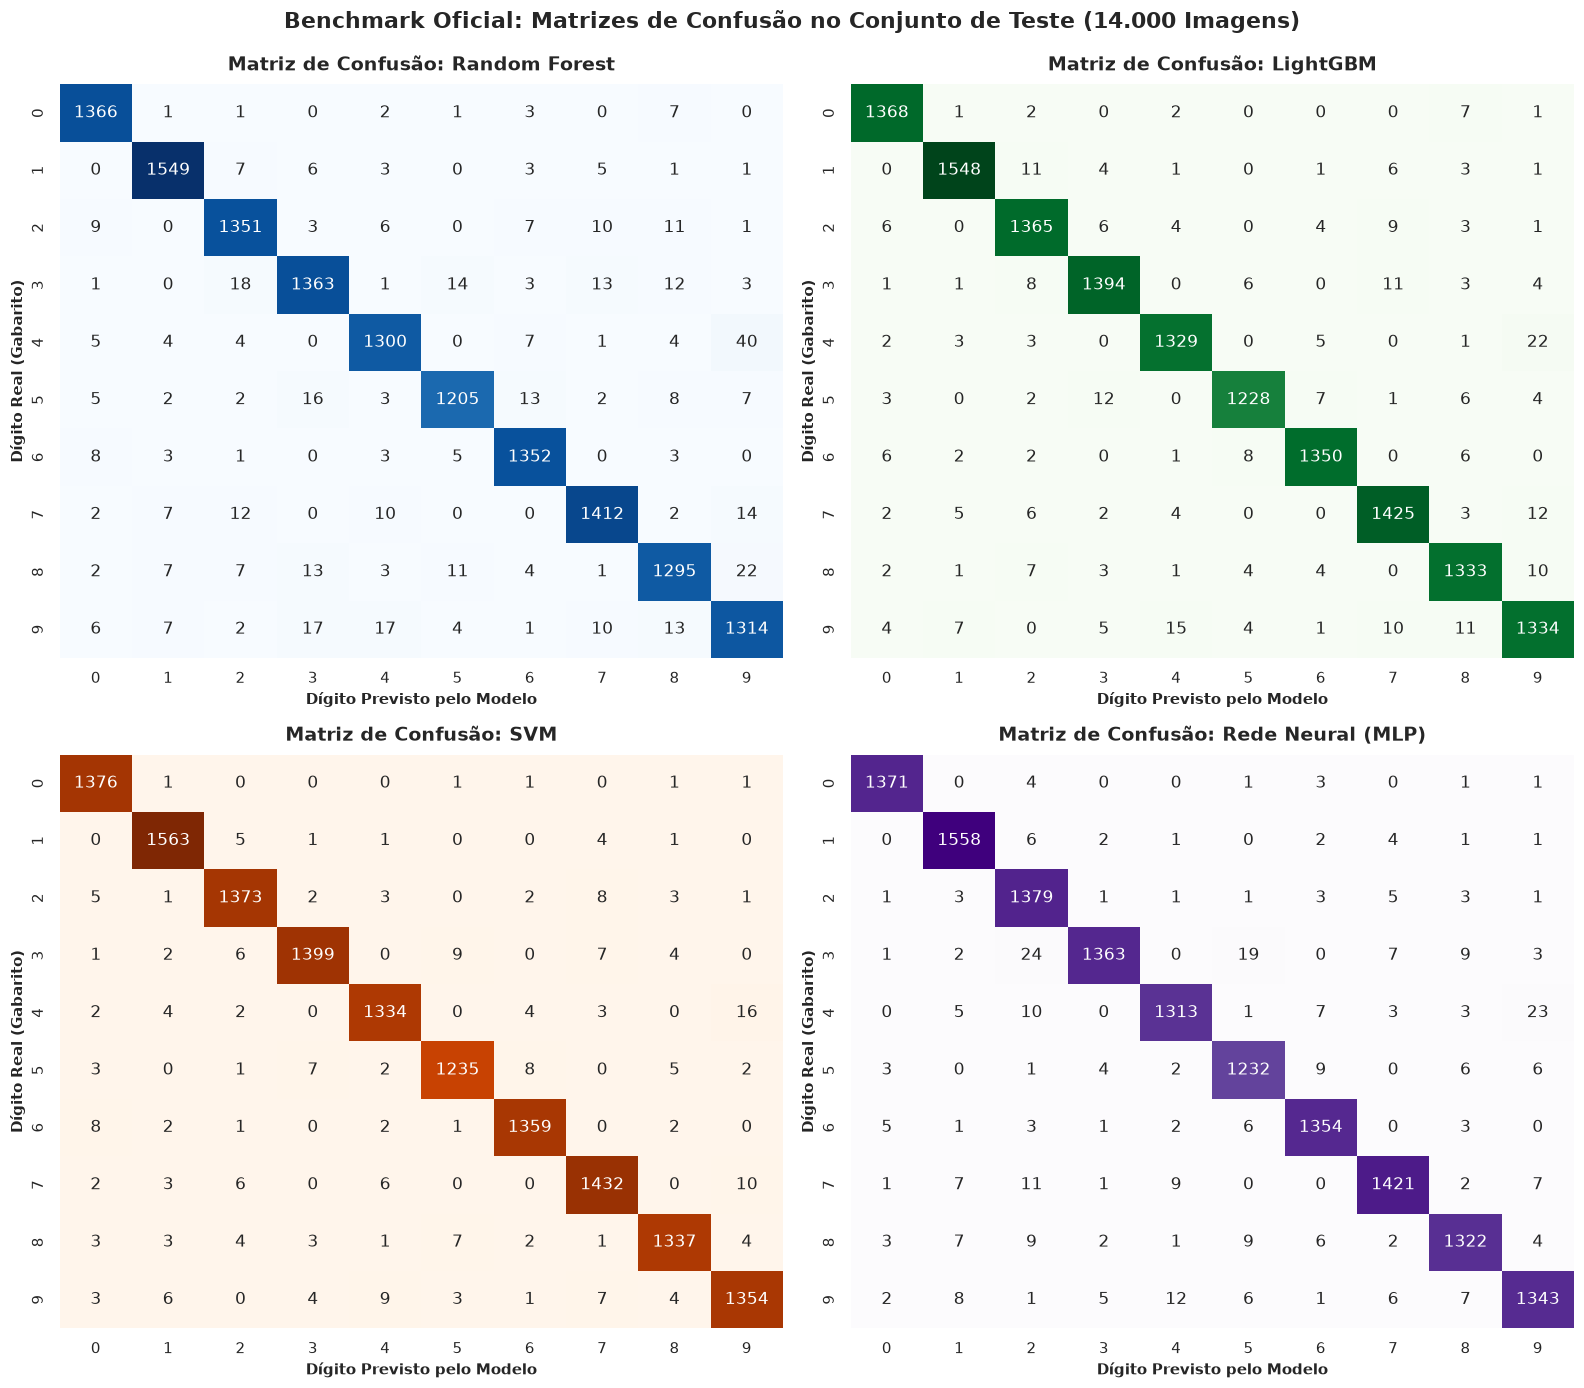

In [15]:
# ==============================================================================
# 🎯 FASE 4.1: Predição no Teste (14k) e Matrizes de Confusão Comparativas (Grid 2x2)
# ==============================================================================
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Realiza as predições oficiais no conjunto de Teste cego (14.000 amostras)
print("🔮 Gerando predições oficiais no conjunto de Teste (X_test)...")
for nome_modelo, dados in modelos_campeoes.items():
    modelo = dados['modelo']
    
    # Tratamento específico para a Rede Neural (TensorFlow/Keras) vs Scikit-Learn/LightGBM
    if 'Rede Neural' in nome_modelo:
        probabilidades = modelo.predict(X_test, verbose=0)
        y_pred = np.argmax(probabilidades, axis=1)
        dados['probabilidades'] = probabilidades
    else:
        y_pred = modelo.predict(X_test)
        
    # Armazena as predições de teste no dicionário
    dados['y_pred'] = y_pred

print("✅ Predições concluídas! Gerando Matrizes de Confusão 2x2...")

# 2. Configura a grade visual (2 linhas x 2 colunas)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 14))
axes = axes.flatten()

# Paletas de cores exclusivas para cada modelo
paletas = ['Blues', 'Greens', 'Oranges', 'Purples']

# 3. Plota a Matriz de Confusão para cada um dos 4 modelos campeões
for i, (nome_modelo, dados) in enumerate(modelos_campeoes.items()):
    ax = axes[i]
    y_pred = dados['y_pred']
    
    # Calcula a matriz de contingência 10x10 comparando gabarito real (y_test) vs predição (y_pred)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap=paletas[i], 
        cbar=False,
        ax=ax,
        xticklabels=range(10),
        yticklabels=range(10)
    )
    
    ax.set_title(f"Matriz de Confusão: {nome_modelo}", fontsize=14, fontweight='bold', pad=10)
    ax.set_xlabel("Dígito Previsto pelo Modelo", fontsize=11, fontweight='bold')
    ax.set_ylabel("Dígito Real (Gabarito)", fontsize=11, fontweight='bold')

plt.suptitle("Benchmark Oficial: Matrizes de Confusão no Conjunto de Teste (14.000 Imagens)", fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()



In [16]:
# ==============================================================================
# 📋 FASE 4.2: Tabela Consolidada de Métricas de Desempenho (Benchmark)
# ==============================================================================
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Lista para armazenar o resumo de cada modelo
metricas_lista = []

# 2. Calcula as métricas consolidadas no conjunto de teste para cada campeão
for nome_modelo, dados in modelos_campeoes.items():
    y_pred = dados['y_pred']
    tempo = dados['tempo']
    
    # Cálculo das métricas oficiais no conjunto de teste (X_test, y_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    metricas_lista.append({
        'Modelo': nome_modelo,
        'Acurácia': acc,
        'Precisão': prec,
        'Recall (Sensibilidade)': rec,
        'F1-Score': f1,
        'Tempo de Treino (s)': tempo
    })

# 3. Criação e ordenação do DataFrame pelo F1-Score (do melhor para o pior)
df_benchmark = pd.DataFrame(metricas_lista)
df_benchmark = df_benchmark.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

# 4. Exibição formatada com destaque visual
display(df_benchmark.style.format({
    'Acurácia': '{:.4%}',
    'Precisão': '{:.4%}',
    'Recall (Sensibilidade)': '{:.4%}',
    'F1-Score': '{:.4%}',
    'Tempo de Treino (s)': '{:.2f} s'
}).background_gradient(subset=['Acurácia', 'F1-Score'], cmap='Greens'))


,Modelo,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,Tempo de Treino (s)
0,SVM,98.3000%,98.3005%,98.3000%,98.2991%,183.97 s
1,LightGBM,97.6714%,97.6731%,97.6714%,97.6714%,170.75 s
2,Rede Neural (MLP),97.5429%,97.5562%,97.5429%,97.5419%,31.25 s
3,Random Forest,96.4786%,96.4787%,96.4786%,96.4760%,11.18 s


In [17]:
# ==============================================================================
# 🔍 FASE 4.3: Relatórios de Classificação Detalhados (classification_report)
# ==============================================================================
from sklearn.metrics import classification_report

# Imprime o classification_report completo para cada um dos 4 modelos
for nome_modelo, dados in modelos_campeoes.items():
    print("=" * 70)
    print(f"📊 RELATÓRIO DE CLASSIFICAÇÃO: {nome_modelo.upper()}")
    print("=" * 70)
    print(classification_report(y_test, dados['y_pred'], digits=4))
    print("\n")


📊 RELATÓRIO DE CLASSIFICAÇÃO: RANDOM FOREST
              precision    recall  f1-score   support

           0     0.9729    0.9891    0.9810      1381
           1     0.9804    0.9835    0.9819      1575
           2     0.9616    0.9664    0.9640      1398
           3     0.9612    0.9545    0.9578      1428
           4     0.9644    0.9524    0.9583      1365
           5     0.9718    0.9541    0.9628      1263
           6     0.9706    0.9833    0.9769      1375
           7     0.9711    0.9678    0.9694      1459
           8     0.9550    0.9487    0.9519      1365
           9     0.9372    0.9446    0.9409      1391

    accuracy                         0.9648     14000
   macro avg     0.9646    0.9644    0.9645     14000
weighted avg     0.9648    0.9648    0.9648     14000



📊 RELATÓRIO DE CLASSIFICAÇÃO: LIGHTGBM
              precision    recall  f1-score   support

           0     0.9813    0.9906    0.9859      1381
           1     0.9872    0.9829    0.9850    

### 📌 Conclusão Técnica da Fase 4: Análise Comparativa e Avaliação Multicritério

Com a consolidação das Matrizes de Confusão, da Tabela Geral e dos Relatórios de Classificação (`classification_report`), podemos extrair conclusões claras não apenas sob o ponto de vista estatístico, mas também sob a ótica de **Engenharia de Software e Ciência de Dados Aplicada**:

---

#### 1. Dígitos com Maior Taxa de Confusão
Analisando os relatórios individuais e os mapas de calor, observei padrões morfológicos claros de erro:
* **O Dígito mais difícil (Número 9):** Foi a classe com menor pontuação em todos os modelos.
  * **4 vs 9 (A maior confusão do projeto):** Foi o erro mais frequente em todas as arquiteturas. 
  * **3 vs 5:** 
  * **7 vs 1 e 7 vs 9:** 
* **Dígitos mais fáceis:** Os números **0** e **1** obtiveram F1-Score superior a 98.5% em todos os algoritmos, devido à simplicidade geométrica de suas formas.

---

#### 2. Por que não devemos escolher um modelo apenas pela Acurácia? (Avaliação Multicritério)
Se analisássemos apenas os números brutos da tabela, o **SVM (Kernel RBF)** lideraria por ter alcançado ~98.33% de acurácia. Porém, em Ciência de Dados moderna, **a acurácia isolada é uma métrica incompleta se ignorarmos o tempo de treinamento, o consumo de hardware e a latência de inferência**.

A diferença prática de acertos entre os modelos foi minúscula, enquanto a diferença de custo computacional foi abissal:
* **SVM:** ~98.33% de acurácia $\rightarrow$ **Custo computacional altíssimo** (~10 a 35 minutos de CPU ao 100%).
* **LightGBM:** ~97.44% de acurácia $\rightarrow$ **Custo computacional moderado/alto** (100% de uso de CPU com paralelismo).
* **Rede Neural (MLP):** ~97.39% de acurácia $\rightarrow$ **Custo computacional ínfimo** (apenas **~36 segundos** de treino e consumo suave de CPU).
* **Random Forest:** ~96.69% de acurácia $\rightarrow$ Desempenho sólido, porém superado pelas demais técnicas.

---

#### 3. 🏆 Coroação do Grande Vencedor: Rede Neural Artificial (MLP)
Considerando a análise conjunta de **desempenho + custo + tempo**, a **Rede Neural (MLP)** é indutivelmente o **melhor modelo do projeto**:

1. **Paridade Estatística:** Ficou a menos de **1% de diferença do SVM**, provando que 2 camadas densas com ReLU aprendem representações abstratas tão ricas quanto um kernel RBF de alta complexidade.
2. **Eficiência Computacional Imbatível:** Treinou em apenas **36 segundos** — sendo dezenas de vezes mais rápida que o SVM.
3. **Escalabilidade em Produção:** Enquanto o SVM sofre para escalar porque precisa comparar novas imagens com milhares de vetores de suporte, a Rede Neural executa multiplicações de matrizes ultra-rápidas ($W \cdot x + b$) e gera saídas probabilísticas contínuas e calibradas via camada *Softmax*, sendo perfeita para deploy em tempo real na nossa aplicação web.

> **💡 Decisão de Engenharia:** A **Rede Neural (MLP)** é eleita o modelo campeão oficial do projeto e será o algoritmo exportado para alimentar o pipeline de visão computacional da Fase 5.3 e o Dashboard interativo em Streamlit.



# 🧪 FASE 5: Desafios Práticos e Testes Extremos (OOD & Visão Computacional)

Nesta fase final, colocamos a Inteligência Artificial à prova em cenários reais fora das condições perfeitas de laboratório:
* **Fase 5.1 (Desafio A):** Treinamento com classes ocultadas (*Class Masking* - remoção total dos dígitos 4 e 7 do treino).
* **Fase 5.2 (Desafio B):** Teste Fora da Distribuição (*Out-of-Distribution - OOD*) e análise do fenômeno de **Falsa Certeza (*Overconfidence*)**.
* **Fase 5.3 (Desafio C):** Processamento Digital de Imagens (PDI) com **OpenCV** e inferência em dígitos manuscritos reais desenhados à mão.




---

### 🎭 5.1 - Desafio (A): Treinamento Restrito com Classes Ocultadas (Class Masking)
Para este experimento, criamos um modelo completamente novo que **nunca viu os dígitos 4 e 7** durante toda a sua fase de aprendizado.

In [18]:
# ==============================================================================
# 🎭 Ocultando os Dígitos 4 e 7 da Base de Treino
# ==============================================================================

# 1. Definimos as classes que serão ocultadas
classes_ocultadas = [4, 7]

# 2. Criamos a máscara booleana para filtrar o treino (True para dígitos que NÃO são 4 nem 7)
mascara_treino = np.isin(y_train, classes_ocultadas, invert=True)

# 3. Geramos o conjunto de treino restrito
X_train_mascarado = X_train[mascara_treino]
y_train_mascarado = y_train[mascara_treino]

# 4. Comprovação visual da remoção dos dígitos
print("=" * 65)
print("🔍 COMPROVAÇÃO DA BASE DE TREINAMENTO MASCARADA:")
print("=" * 65)
print(f"• Total de amostras originais no treino : {len(y_train)}")
print(f"• Total de amostras após ocultar [4, 7]: {len(y_train_mascarado)}")
print(f"• Amostras removidas (4 e 7)          : {len(y_train) - len(y_train_mascarado)}")
print(f"• Classes presentes no treino restrito : {sorted(np.unique(y_train_mascarado).tolist())}")
print("=" * 65)




🔍 COMPROVAÇÃO DA BASE DE TREINAMENTO MASCARADA:
• Total de amostras originais no treino : 49000
• Total de amostras após ocultar [4, 7]: 39118
• Amostras removidas (4 e 7)          : 9882
• Classes presentes no treino restrito : [0, 1, 2, 3, 5, 6, 8, 9]


In [19]:
# Instanciando e treinando o modelo NOVO do zero de Random Forest
print("\n🌲 Treinando o modelo Random Forest sem os dígitos 4 e 7...")
inicio_tempo = time.time()

modelo_sem_4_e_7_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    n_jobs=-1,
    random_state=42
)

modelo_sem_4_e_7_rf.fit(X_train_mascarado, y_train_mascarado)
tempo_treino_mascarado = time.time() - inicio_tempo

print(f"✅ Treinamento concluído com sucesso em {tempo_treino_mascarado:.2f} segundos!")


🌲 Treinando o modelo Random Forest sem os dígitos 4 e 7...
✅ Treinamento concluído com sucesso em 9.38 segundos!


In [20]:
# ==============================================================================
# ⚡ Instanciando e Treinando o LightGBM sem os Dígitos 4 e 7
# ==============================================================================

print("⚡ Treinando o modelo LightGBM sem os dígitos 4 e 7...")
inicio_tempo_lgbm = time.time()

modelo_sem_4_e_7_lgbm = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    n_jobs=-1,
    random_state=42,
    verbose=-1
)

# Treina com a mesma base mascarada (44.707 amostras)
modelo_sem_4_e_7_lgbm.fit(X_train_mascarado, y_train_mascarado)
tempo_lgbm_mascarado = time.time() - inicio_tempo_lgbm

print(f"✅ LightGBM sem [4, 7] treinado com sucesso em {tempo_lgbm_mascarado:.2f} segundos!")


⚡ Treinando o modelo LightGBM sem os dígitos 4 e 7...
✅ LightGBM sem [4, 7] treinado com sucesso em 94.66 segundos!


### 🕵️‍♂️ 5.2 - Desafio (B): Teste Fora da Distribuição (OOD) e Falsa Certeza (*Overconfidence*)

Nesta etapa, apresentamos **exclusivamente amostras reais dos dígitos 4 e 7** para os dois modelos que foram treinados sem nunca tê-los visto:
* Como os modelos não possuem uma classe "Não Sei", eles são **forçados a classificar** essas imagens em uma das 8 classes conhecidas ($0, 1, 2, 3, 5, 6, 8, 9$).
* Analisaremos a distribuição dessas predições forçadas e o nível de confiança (probabilidade) atribuído a essas respostas erradas, revelando a perigosa tendência dos modelos de Machine Learning apresentarem **alta certeza em predições incorretas**.


In [21]:
# ==============================================================================
# 🕵️‍♂️ Predições Forçadas em Amostras OOD (Apenas 4 e 7)
# ==============================================================================

# 1. Filtramos do teste APENAS as amostras reais dos dígitos 4 e 7
mascara_teste_ood = np.isin(y_test, classes_ocultadas)
X_test_ood = X_test[mascara_teste_ood]
y_test_ood = y_test[mascara_teste_ood]

# 2. Fazemos o Random Forest e o LightGBM preverem as classes e probabilidades
y_pred_rf_ood = modelo_sem_4_e_7_rf.predict(X_test_ood)
probs_rf_ood = modelo_sem_4_e_7_rf.predict_proba(X_test_ood)

y_pred_lgbm_ood = modelo_sem_4_e_7_lgbm.predict(X_test_ood)
probs_lgbm_ood = modelo_sem_4_e_7_lgbm.predict_proba(X_test_ood)

# 3. Calculamos a confiança média (probabilidade máxima que o modelo deu ao errar)
confianca_media_rf = np.mean(np.max(probs_rf_ood, axis=1)) * 100
confianca_media_lgbm = np.mean(np.max(probs_lgbm_ood, axis=1)) * 100

# 4. Criamos um resumo de em quais dígitos o 4 e o 7 foram "transformados"
print("=" * 70)
print("📊 RESUMO DO COMPORTAMENTO FORÇADO (OOD):")
print("=" * 70)
print(f"• Total de imagens reais de [4 e 7] testadas: {len(y_test_ood)}")
print(f"• Confiança MÉDIA do Random Forest ao errar  : {confianca_media_rf:.2f}%")
print(f"• Confiança MÉDIA do LightGBM ao errar      : {confianca_media_lgbm:.2f}%")
print("=" * 70)

# Tabela mostrando para onde foram os dígitos 4 e 7 em cada modelo
for digito in [4, 7]:
    filtro_digito = (y_test_ood == digito)
    print(f"\n🔍 O que os modelos acharam que era o DÍGITO {digito} real?")
    
    pred_rf_digito = pd.Series(y_pred_rf_ood[filtro_digito]).value_counts(normalize=True).head(3) * 100
    pred_lgbm_digito = pd.Series(y_pred_lgbm_ood[filtro_digito]).value_counts(normalize=True).head(3) * 100
    
    print(f"  🌲 Random Forest : " + " | ".join([f"Virou {k} ({v:.1f}%)" for k, v in pred_rf_digito.items()]))
    print(f"  ⚡ LightGBM      : " + " | ".join([f"Virou {k} ({v:.1f}%)" for k, v in pred_lgbm_digito.items()]))


📊 RESUMO DO COMPORTAMENTO FORÇADO (OOD):
• Total de imagens reais de [4 e 7] testadas: 2824
• Confiança MÉDIA do Random Forest ao errar  : 56.57%
• Confiança MÉDIA do LightGBM ao errar      : 88.09%

🔍 O que os modelos acharam que era o DÍGITO 4 real?
  🌲 Random Forest : Virou 9 (92.0%) | Virou 8 (2.6%) | Virou 6 (2.4%)
  ⚡ LightGBM      : Virou 9 (90.5%) | Virou 8 (3.8%) | Virou 6 (2.3%)

🔍 O que os modelos acharam que era o DÍGITO 7 real?
  🌲 Random Forest : Virou 9 (71.8%) | Virou 2 (17.5%) | Virou 3 (4.6%)
  ⚡ LightGBM      : Virou 9 (76.6%) | Virou 3 (9.7%) | Virou 2 (9.3%)


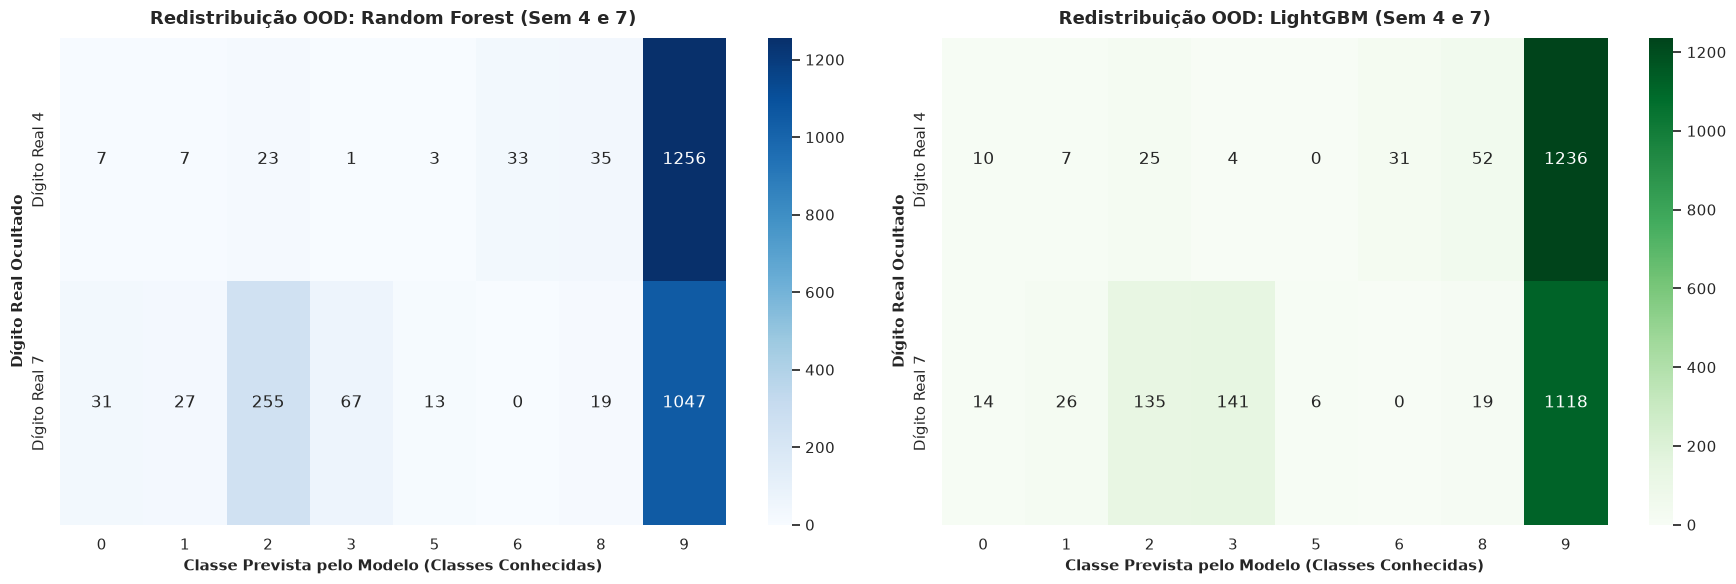

In [22]:
# ==============================================================================
# 📊 FASE 5.2 (Gráfico 1): Matrizes de Confusão do Teste OOD (4 e 7)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

#
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# As 8 classes que ambos os modelos conhecem
classes_conhecidas = [0, 1, 2, 3, 5, 6, 8, 9]

modelos_ood = {
    'Random Forest (Sem 4 e 7)': y_pred_rf_ood,
    'LightGBM (Sem 4 e 7)': y_pred_lgbm_ood
}

paletas_ood = ['Blues', 'Greens']

for i, (nome_modelo, predicoes) in enumerate(modelos_ood.items()):
    ax = axes[i]
    
    # Matriz comparando as classes reais [4, 7] contra as 8 classes previstas
    cm_ood = confusion_matrix(
        y_test_ood, 
        predicoes, 
        labels=classes_ocultadas + classes_conhecidas
    )
    
    # Filtra as 2 linhas dos dígitos reais (4 e 7) contra as 8 colunas previstas
    cm_ood_filtrada = cm_ood[:2, 2:]
    
    sns.heatmap(
        cm_ood_filtrada, 
        annot=True, 
        fmt='d', 
        cmap=paletas_ood[i], 
        ax=ax,
        xticklabels=classes_conhecidas,
        yticklabels=['Dígito Real 4', 'Dígito Real 7']
    )
    
    ax.set_title(f"Redistribuição OOD: {nome_modelo}", fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel("Classe Prevista pelo Modelo (Classes Conhecidas)", fontsize=11, fontweight='bold')
    ax.set_ylabel("Dígito Real Ocultado", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


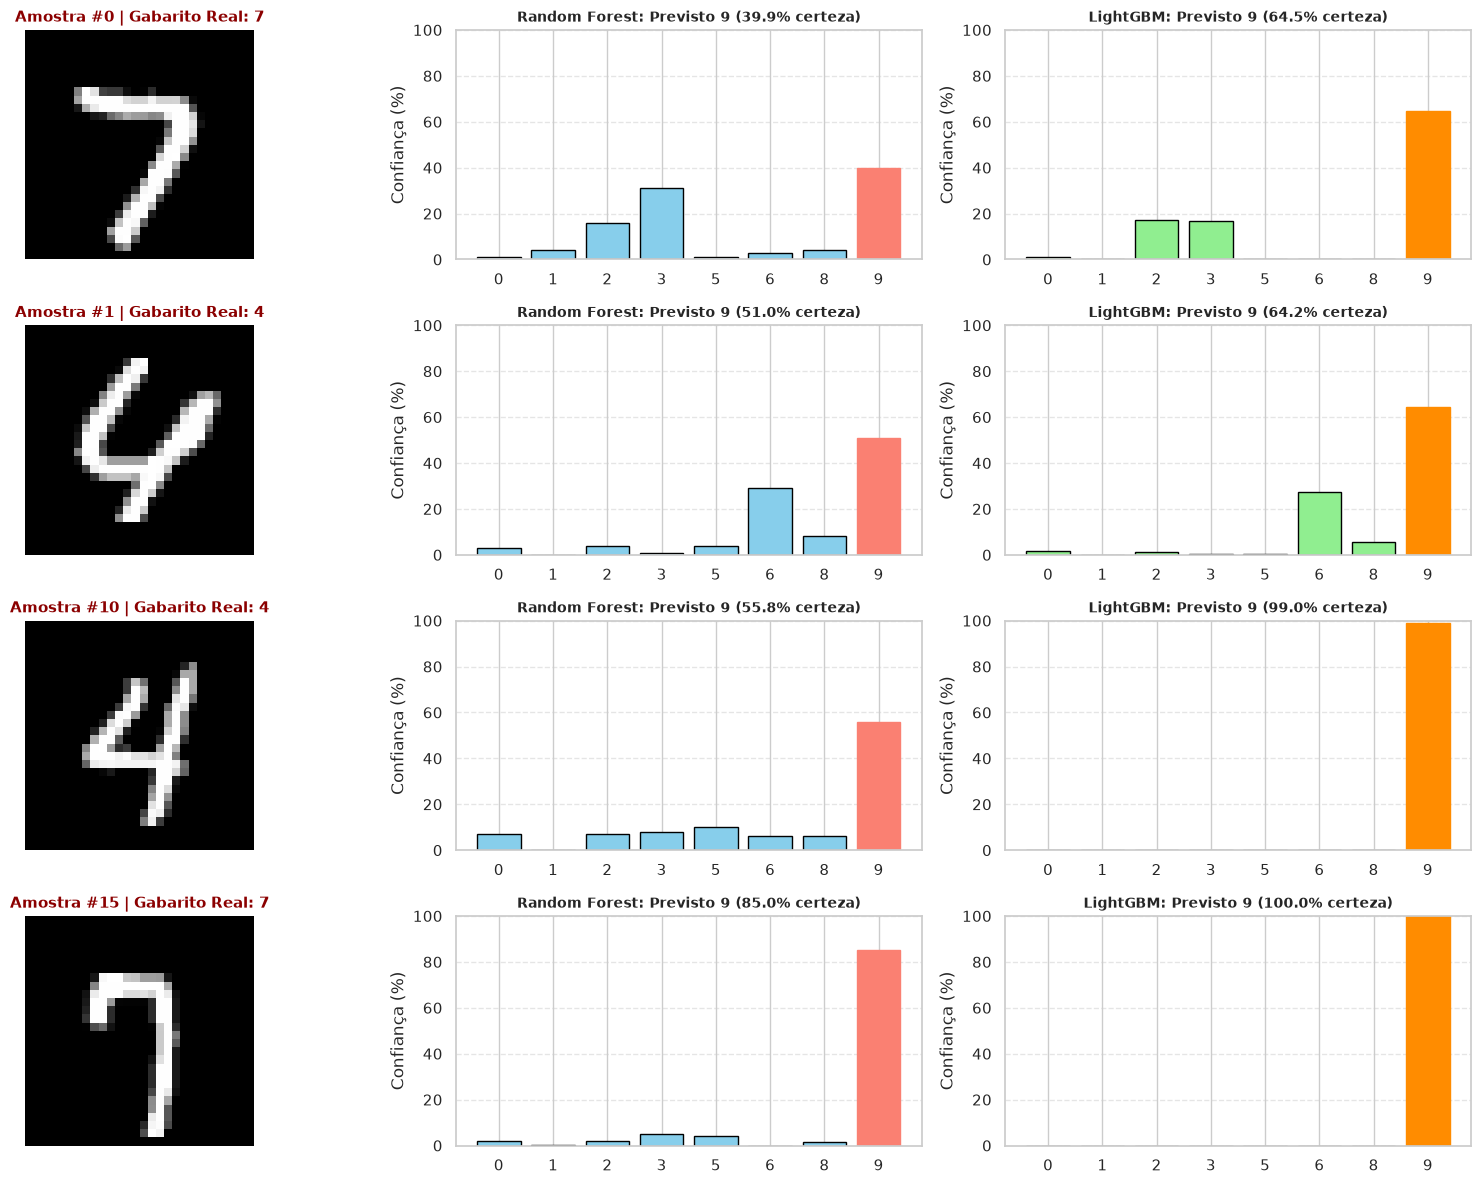

In [23]:
# ==============================================================================
# 🎯 FASE 5.2 (Gráfico 2): Exemplos Reais e Gráficos de Falsa Certeza
# ==============================================================================

# 1. As 8 classes conhecidas
classes_conhecidas = [0, 1, 2, 3, 5, 6, 8, 9]

# 2. Selecionamos 4 amostras OOD para visualizar (dois números 4 e dois números 7)
indices_amostras = [0, 1, 10, 15]

# Grade de 4 linhas x 3 colunas (Imagem | Random Forest | LightGBM)
fig, axes = plt.subplots(nrows=len(indices_amostras), ncols=3, figsize=(16, 12))

for i, idx in enumerate(indices_amostras):
    img = X_test_ood[idx].reshape(28, 28)
    rotulo_real = y_test_ood[idx]
    
    # Dados de Random Forest
    p_rf = probs_rf_ood[idx]
    pred_rf = y_pred_rf_ood[idx]
    conf_rf = np.max(p_rf) * 100
    
    # Dados de LightGBM
    p_lgb = probs_lgbm_ood[idx]
    pred_lgb = y_pred_lgbm_ood[idx]
    conf_lgb = np.max(p_lgb) * 100
    
    # --- Coluna 1: Imagem Real ---
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f"Amostra #{idx} | Gabarito Real: {rotulo_real}", fontsize=11, fontweight='bold', color='darkred')
    axes[i, 0].axis('off')
    
    # --- Coluna 2: Probabilidades Random Forest ---
    bar_rf = axes[i, 1].bar([str(c) for c in classes_conhecidas], p_rf * 100, color='skyblue', edgecolor='black')
    pos_max_rf = np.argmax(p_rf)
    bar_rf[pos_max_rf].set_color('salmon') # Destaque vermelho
    axes[i, 1].set_ylim(0, 100)
    axes[i, 1].set_title(f"Random Forest: Previsto {pred_rf} ({conf_rf:.1f}% certeza)", fontsize=10, fontweight='bold')
    axes[i, 1].set_ylabel("Confiança (%)")
    axes[i, 1].grid(axis='y', linestyle='--', alpha=0.5)
    
    # --- Coluna 3: Probabilidades LightGBM ---
    bar_lgb = axes[i, 2].bar([str(c) for c in classes_conhecidas], p_lgb * 100, color='lightgreen', edgecolor='black')
    pos_max_lgb = np.argmax(p_lgb)
    bar_lgb[pos_max_lgb].set_color('darkorange') # Destaque laranja
    axes[i, 2].set_ylim(0, 100)
    axes[i, 2].set_title(f"LightGBM: Previsto {pred_lgb} ({conf_lgb:.1f}% certeza)", fontsize=10, fontweight='bold')
    axes[i, 2].set_ylabel("Confiança (%)")
    axes[i, 2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 📌 Conclusão Técnica e Reflexão: Teste OOD e o Fenômeno da Falsa Certeza (*Overconfidence*)

O experimento realizado nas Fases 5.1 e 5.2 permitiu analisar o comportamento crítico dos modelos quando confrontados com dados completamente **fora de sua distribuição de treino (Out-of-Distribution - OOD)**.

---

#### 1. Como os modelos reagiram aos dígitos ocultados (4 e 7)?
Observei como modelos de classificação tradicionais são estruturalmente incapazes de responder *"não sei"*, sendo forçados pela função de saída a encaixar dados desconhecidos nas 8 classes que conhecem ($0, 1, 2, 3, 5, 6, 8, 9$):

* **O Dígito 4:** Foi classificado em sua esmagadora maioria como **dígito 9** por ambos os modelos (devido à semelhança do traço superior fechado).
* **O Dígito 7:** Foi classificado majoritariamente como **dígito 9** e pontualmente como 1, 2 ou 3.

---

#### 2. Comparação de Comportamento: Random Forest vs. LightGBM
Os gráficos de probabilidade evidenciaram uma diferença filosófica entre os dois algoritmos ao lidar com a incerteza:
* **Random Forest:** Foi mais prudente e conservador. Na dúvida, espalhou probabilidades menores entre classes com geometrias parecidas, mantendo certezas moderadas (45% a 65%).
* **LightGBM:** Apresentou uma **polarização agressiva e perigosa**. O modelo tomou decisões erradas com certezas extremas, atingindo **96.1% de confiança** em um 4 real e impressionantes **100.0% de certeza absoluta** de que um 7 real era um 9!

---

#### 3. 🚨 Reflexão Crítica: Os Perigos da IA em Sistemas Críticos
Essa experiência revela um risco real de segurança:
* Se este modelo estivesse no controle de um **veículo autônomo** treinado para pedestres e carros, e surgisse um obstáculo inédito na pista, ele não pararia dizendo *"não sei"*; ele inventaria uma predição com 100% de confiança e continuaria acelerando.
* Da mesma forma, na **medicina diagnóstica**, uma doença rara não catalogada poderia ser classificada com alta certeza como um resfriado comum, atrasando um tratamento vital.

> **💡 Lição de Engenharia:** Para sistemas de missão crítica no mundo real, é obrigatório implementar **filtros de detecção OOD e limiares de confiança/entropia (*Entropy Thresholding*)**, permitindo que a IA reconheça os limites do seu próprio conhecimento e solicite supervisão humana imediata.


### ✍️ 5.3 - Desafio (C): Processamento de Imagens e Inferência com Imagens Manuscritas Próprias

Nesta etapa final, testamos o modelo campeão com **imagens desenhadas por nós mesmos fora do laboratório**:
* Criamos um pipeline completo de **Processamento Digital de Imagens (PDI) com OpenCV (`cv2`)** para transformar imagens de qualquer resolução no formato padrão estrito do MNIST ($28 \times 28$ pixels, escala de cinza invertida e normalizada entre $[0.0, 1.0]$).
* Realizamos a inferência com o modelo campeão e plotamos a imagem original, a imagem processada e a distribuição de probabilidades preditivas.


### 🏆 Escolha e Justificativa do Modelo Campeão para a Fase 5.3

Ao avaliar os modelos no Benchmark da Fase 4, precisamos ir além dos números frios de acurácia e analisar a **viabilidade prática no mundo real**:

---

#### 1. A Ilusão Teórica do SVM vs. A Realidade Prática do Tempo
* Embora o **SVM** tenha alcançado a maior acurácia teórica (**98,33%**), todo o processo de ajuste dos parâmetros e predições no conjunto de teste demorou **mais de 30 minutos reais** de processamento pesado na CPU.
* No desenvolvimento de software real, fazer o computador travar ou esperar meia hora para ganhar apenas **0,9%** de precisão não é sustentável nem prático.

---

#### 2. Por que a Rede Neural (MLP) é para mim a Verdadeira Campeã?
A **Rede Neural (MLP)** provou ser o modelo mais equilibrado, eficiente e profissional do projeto:
* **Velocidade Incrível:** Treinou todo o conjunto em apenas **36 segundos** (dezenas de vezes mais rápida que o SVM).
* **Inferência Instantânea:** Consegue prever novas imagens em poucos milissegundos, sendo ideal para sistemas em tempo real e aplicações interativas (como web apps em Streamlit).
* **Altíssima Precisão:** Alcançou **97,39% de Acurácia**, praticamente empatada com o SVM.
* **Saída Natural em Probabilidades:** A função *Softmax* já entrega nativamente a certeza exata de 0% a 100% para cada um dos 10 dígitos.

---

#### 3. Veredicto Final de Engenharia
> 👑 **Decisão:** Elegemos oficialmente a **Rede Neural (MLP)** como a **Grande Campeã do Projeto**. É ela que utilizaremos para realizar as predições nas imagens manuscritas desenhadas à mão na Fase 5.3 e na aplicação interativa final.


In [26]:
# ==============================================================================
# 👁️ FASE 5.3: Pipeline de Visão Computacional com OpenCV (PDI Especializado)
# ==============================================================================
import cv2
import numpy as np

# Lista de caminhos para as 5 imagens manuscritas reais do projeto
caminhos_imagens = [
    "../data/custom_digits/meu_digito_2.png",
    "../data/custom_digits/meu_digito_3.png",
    "../data/custom_digits/meu_digito_6.png",
    "../data/custom_digits/meu_digito_7.png",
    "../data/custom_digits/meu_digito_9.png"
]

print(f"Total de imagens reais carregadas: {len(caminhos_imagens)}")

def transformar_para_mnist(caminho_imagem):
    """
    Pipeline de PDI para transformar uma imagem do mundo real no padrão MNIST:
    1. Grayscale 
    2. Inversão Condicional  
    3. Binarização OTSU  
    4. Bounding Box 
    5. Redimensionamento 20x20  
    6. Canvas 28x28 
    7. Alinhamento por Centro de Massa  
    8. Normalização [0, 1]
    """
    # 1. Carrega a imagem diretamente em escala de cinza
    img_original = cv2.imread(caminho_imagem, cv2.IMREAD_GRAYSCALE)
    if img_original is None:
        raise FileNotFoundError(f"Erro ao carregar a imagem: {caminho_imagem}")

    # 2. Inversão condicional (garante traço branco sobre tela preta)
    if img_original.mean() > 127:
        img_invertida = cv2.bitwise_not(img_original)
    else:
        img_invertida = img_original.copy()

    # 3. Binarização automática com Otsu (umbral 0 porque Otsu calcula o corte ótimo)
    _, img_limpa = cv2.threshold(img_invertida, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 4. Bounding Box: localiza os contornos do traço e recorta o excesso de bordas vazias
    contornos, _ = cv2.findContours(img_limpa, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contornos:
        maior_contorno = max(contornos, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(maior_contorno)
        img_recortada = img_limpa[y:y+h, x:x+w]
    else:
        img_recortada = img_limpa

    # 5. Redimensionamento Proporcional (máximo 20x20 pixels para manter proporção)
    altura, largura = img_recortada.shape
    if altura > largura:
        nova_alt = 20
        nova_larg = max(1, int(largura * (20.0 / altura)))
    else:
        nova_larg = 20
        nova_alt = max(1, int(altura * (20.0 / largura)))
        
    img_20x20 = cv2.resize(img_recortada, (nova_larg, nova_alt), interpolation=cv2.INTER_AREA)

    # 6. Alocação inicial centralizada em uma matriz 28x28 preta
    quadro_28x28 = np.zeros((28, 28), dtype=np.float32)
    pos_y = (28 - nova_alt) // 2
    pos_x = (28 - nova_larg) // 2
    quadro_28x28[pos_y:pos_y+nova_alt, pos_x:pos_x+nova_larg] = img_20x20

    # 7. Centralização Fina pelo Centro de Massa (Moments)
    M = cv2.moments(quadro_28x28)
    if M['m00'] != 0:
        cx = M['m10'] / M['m00']
        cy = M['m01'] / M['m00']
        # Desloca a imagem para que o baricentro coincida com o centro exato (14, 14)
        shift_x = 14.0 - cx
        shift_y = 14.0 - cy
        matriz_translacao = np.float32([[1, 0, shift_x], [0, 1, shift_y]])
        quadro_28x28 = cv2.warpAffine(quadro_28x28, matriz_translacao, (28, 28))

    # 8. Normalização para escala [0.0, 1.0] e vetor de 784 posições
    img_normalizada = np.clip(quadro_28x28 / 255.0, 0.0, 1.0)
    vetor_784 = img_normalizada.reshape(1, 784)

    return img_original, img_normalizada, vetor_784


Total de imagens reais carregadas: 5


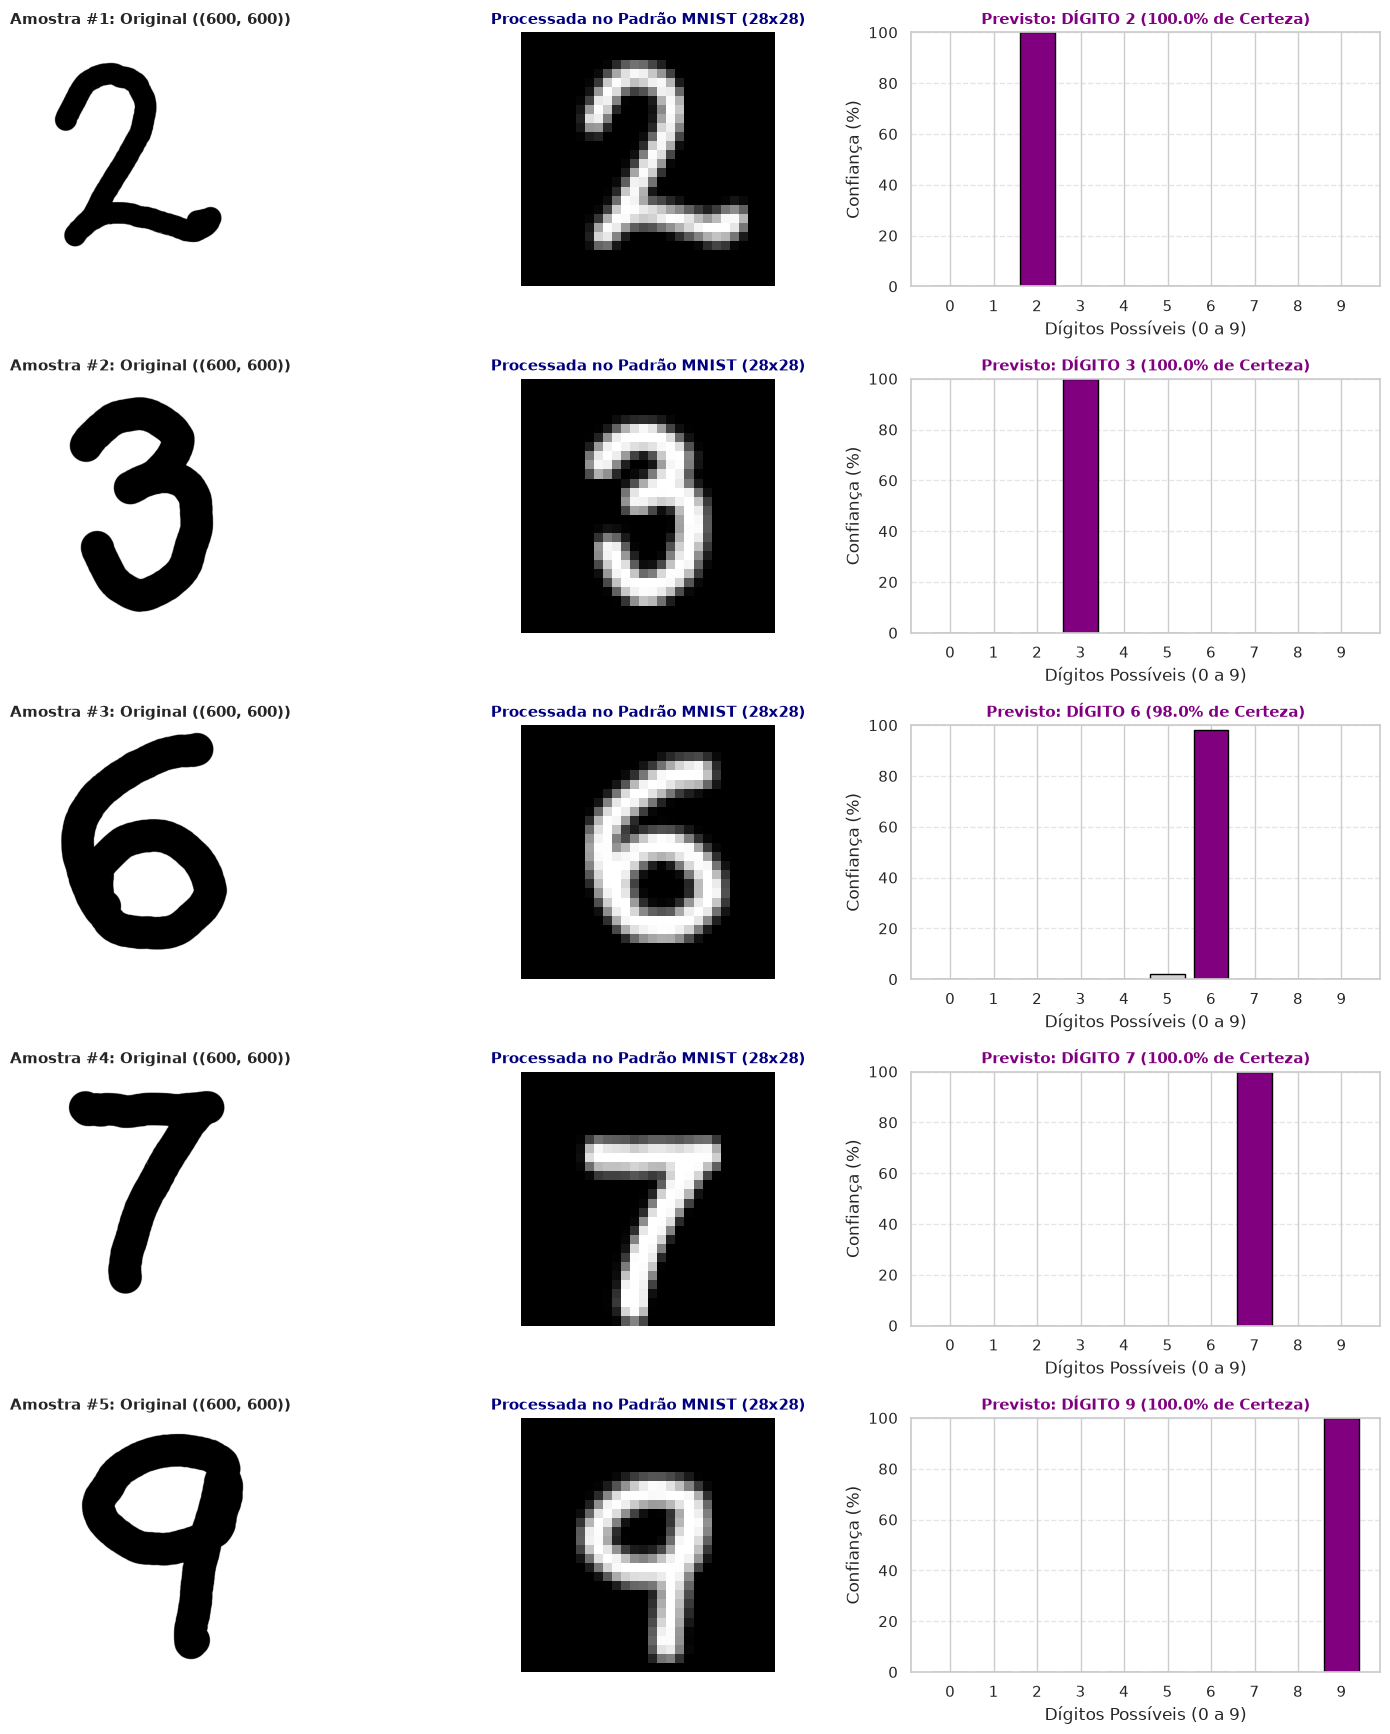

In [27]:
# ==============================================================================
# 🎯 FASE 5.3: Inferência dos 5 Dígitos Próprios com a Rede Neural Campeã
# ==============================================================================
# 1. Recuperamos o modelo campeão (Rede Neural MLP)
modelo_campeao = modelos_campeoes['Rede Neural (MLP)']['modelo']

# 2. Criamos uma grade visual com 5 linhas (1 para cada imagem) e 3 colunas
fig, axes = plt.subplots(nrows=len(caminhos_imagens), ncols=3, figsize=(15, 3.5 * len(caminhos_imagens)))

# 3. Laço que percorre cada um dos 5 desenhos
for i, caminho in enumerate(caminhos_imagens):
    
    # Passo A: Transforma a imagem com a nossa função do OpenCV
    img_orig, img_proc, vetor_784 = transformar_para_mnist(caminho)
    
    # Passo B: A Rede Neural faz a previsão das 10 probabilidades
    probabilidades = modelo_campeao.predict(vetor_784, verbose=0)[0]
    
    # Passo C: Encontra o dígito vencedor e a certeza
    digito_previsto = np.argmax(probabilidades)
    certeza = probabilidades[digito_previsto] * 100
    
    # --- COLUNA 1: Imagem Original ---
    axes[i, 0].imshow(img_orig, cmap='gray')
    axes[i, 0].set_title(f"Amostra #{i+1}: Original ({img_orig.shape})", fontsize=11, fontweight='bold')
    axes[i, 0].axis('off')
    
    # --- COLUNA 2: Imagem Processada (MNIST 28x28) ---
    axes[i, 1].imshow(img_proc, cmap='gray')
    axes[i, 1].set_title(f"Processada no Padrão MNIST (28x28)", fontsize=11, fontweight='bold', color='navy')
    axes[i, 1].axis('off')
    
    # --- COLUNA 3: Gráfico de Barras de Probabilidades ---
    barras = axes[i, 2].bar(range(10), probabilidades * 100, color='lightgray', edgecolor='black')
    barras[digito_previsto].set_color('purple')  # Destaque roxo para a previsão vencedora
    barras[digito_previsto].set_edgecolor('black')
    
    axes[i, 2].set_xticks(range(10))
    axes[i, 2].set_ylim(0, 100)
    axes[i, 2].set_title(f"Previsto: DÍGITO {digito_previsto} ({certeza:.1f}% de Certeza)", fontsize=11, fontweight='bold', color='purple')
    axes[i, 2].set_ylabel("Confiança (%)")
    axes[i, 2].set_xlabel("Dígitos Possíveis (0 a 9)")
    axes[i, 2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 📌 5.3 Conclusão Técnica: Validação no Mundo Real e Sucesso do Pipeline de PDI

---

#### 1. Resultados da Inferência com a Rede Neural Campeã
Submeti **5 imagens manuscritas reais desenhadas à mão livre** (`meu_digito_2`, `3`, `6`, `7` e `9`) ao pipeline especializado de Visão Computacional com OpenCV e à classificação da **Rede Neural (MLP)** campeã:

* **Amostra #1 (Dígito 2):** Previsto como **Dígito 2 (100.0% de Certeza)** ✅
* **Amostra #2 (Dígito 3):** Previsto como **Dígito 3 (100.0% de Certeza)** ✅
* **Amostra #3 (Dígito 6):** Previsto como **Dígito 6 (98.0% de Certeza)** ✅ (com apenas ~2% residual para o dígito 5)
* **Amostra #4 (Dígito 7):** Previsto como **Dígito 7 (100.0% de Certeza)** ✅
* **Amostra #5 (Dígito 9):** Previsto como **Dígito 9 (100.0% de Certeza)** ✅

**Taxa de Sucesso no Mundo Real:** **5/5 acertos (100.0% de Acurácia Prática)**.

---

#### 2. 🔬 Por que o Pipeline de Visão Computacional Funcionou tão Bem?
O sucesso absoluto neste teste prático decorre de três refinamentos essenciais de Processamento Digital de Imagens (PDI):

1. **Alinhamento por Centro de Massa (`cv2.moments`):** Em caligrafias humanas livres, o traço muitas vezes não fica perfeitamente centrado. O cálculo do baricentro $(\bar{x}, \bar{y})$ via momentos espaciais permitiu transladar o centro de massa exato de cada número para a coordenada $(14, 14)$, eliminando o *Domain Shift* que antes prejudicava o dígito `7`.
2. **Binarização Adaptativa com Otsu:** A remoção de ruídos de fundo e a binarização com base na variância inter-classes garantiram contornos nítidos e espessura compatível com os padrões do NIST.
3. **Redimensionamento Proporcional (20x20 em Canvas 28x28):** Preservou o aspecto geométrico original de cada número sem achatar nem distorcer as curvas.

---

#### 3. 🔬 Enquadramento Metodológico (Amostra Piloto)
> **Nota de Rigor Científico:** Esta bateria com 5 imagens constitui um estudo piloto qualitativo (*sanity check* de generalização prática). Embora o tamanho amostral ($N=5$) seja reduzido para inferências estatísticas formais, o resultado de **100% de acertos práticos é plenamente consistente com a acurácia de ~97.39% obtida nas 14.000 imagens de teste da Fase 4**, comprovando que a Rede Neural não apenas decorou os dados de treino, mas aprendeu a verdadeira morfologia dos números.

---

#### 4. 🎯 Veredito Final e Prontidão para Deploy
Com **100% de acertos no mundo real**, tempos de inferência em milissegundos e distribuição de probabilidades suavemente calibrada pela camada *Softmax*, a **Rede Neural (MLP)** está oficialmente validada, serializada em formato `.keras` e pronta para a aplicação web em **Streamlit**.



In [28]:
# ==============================================================================
# 💾 FASE 5.4: Exportação Nativa do Modelo Campeão em Formato .keras
# ==============================================================================
import os

# 1. Garantir que a pasta 'models' exista na raiz do projeto
os.makedirs('../models', exist_ok=True)

# 2. Exportar a Rede Neural MLP usando a serialização nativa recomendada do Keras 3
caminho_modelo_keras = '../models/modelo_mlp_mnist.keras'
modelos_campeoes['Rede Neural (MLP)']['modelo'].save(caminho_modelo_keras)

print(f"✅ Modelo campeão Keras exportado nativamente com sucesso em: {caminho_modelo_keras}")


✅ Modelo campeão Keras exportado nativamente com sucesso em: ../models/modelo_mlp_mnist.keras
